# Recent Holiday Trends and Traveller Behaviour Survey


## The purpose of this survey is to explore recent holiday trends and traveller behaviour. This survey forms part of an academic project for the Statistical Techniques for Data Analytics module.

## Add python libraries to analysis

In [39]:
import pandas as pd
import seaborn as sns
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np

# Data Preparation

## Load the Dataset

In [40]:
df_Holidays = pd.read_csv("Data_CA1.csv")

## Data Cleaning

### Display first 5 rows, to ensure the data has correctly loaded


In [41]:
df_Holidays.head(5)

,Timestamp,What age range are you in?,Was your holiday,What was the main purpose of your Holiday,How did you book your holiday,How recent was this holiday,How would you describe your holiday type,How many people were in your travel group?,Approximately how much did your accommodation cost per room per night (€)?,How many nights did your holiday last?,"Overall Holiday Cost - Approximate total spend for all travellers (€), including cost of holiday + daily spending.",How satisfied were you with your holiday overall?,Would You Take This Type of Holiday Again?,Did You Travel by Air?,How many holidays have you taken in the last 12 months?
0,25/09/2026 12:25,65+,A Holiday abroad (outside Ireland),"To attend an event (concert, Football match etc)",Independently Booked online,Greater than 3 months ago but within the last ...,A holiday with friends,6,100,3,800,5,Yes,Yes,2
1,25/09/2026 12:25,55-64,A Holiday abroad (outside Ireland),Beach Holiday abroad,A package holiday,In last 3 months,A family holiday,2,150,5,3000,3,Yes,Yes,3
2,25/09/2026 12:27,65+,A Holiday abroad (outside Ireland),Beach Holiday abroad,Independently Booked online,In last 3 months,A family holiday,4,70,28,4800,5,Yes,No,4
3,25/09/2026 12:29,65+,A Holiday abroad (outside Ireland),City Break,Independently Booked online,Greater than 3 months ago but within the last ...,A holiday with friends,6,50,3,500,5,Yes,Yes,2
4,25/09/2026 12:32,25-34,A Holiday abroad (outside Ireland),Other,Independently Booked online,Greater than 3 months ago but within the last ...,A holiday with friends,3,115,6,3000,5,Yes,Yes,3


####  Trim any spaces from the headings

In [42]:
df_Holidays.columns = df_Holidays.columns.str.strip()

## Missing Value Analysis

In [43]:
df_Holidays.isnull().sum()

Timestamp                                                                                                              0
What age range are you in?                                                                                             0
Was your holiday                                                                                                       0
What was the main purpose of your Holiday                                                                              0
How did you book your holiday                                                                                          0
How recent was this holiday                                                                                            0
How would you describe your holiday type                                                                               0
How many people were in your travel group?                                                                             0
Approximately how much did your 

### No missing values were identified in the dataset. Therefore no records required removal

In [44]:
df_Holidays.shape

(71, 15)

In [45]:
df_Holidays.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 15 columns):
 #   Column                                                                                                               Non-Null Count  Dtype 
---  ------                                                                                                               --------------  ----- 
 0   Timestamp                                                                                                            71 non-null     object
 1   What age range are you in?                                                                                           71 non-null     object
 2   Was your holiday                                                                                                     71 non-null     object
 3   What was the main purpose of your Holiday                                                                            71 non-null     object
 4   How did you book your 

# Rename columns to make it more readable 

In [46]:
df_Holidays = df_Holidays.rename(columns={
    "Timestamp": "Timestamp",
    "What age range are you in?": "Age_Range",
    "Was your holiday": "Holiday_Location",
    "What was the main purpose of your Holiday": "Holiday_Purpose",
    "How did you book your holiday": "Booking_Method",
    "How recent was this holiday": "Holiday_Recency",
    "How would you describe your holiday type": "Holiday_Type",
    "How many people were in your travel group?": "Group_Size",
    "Approximately how much did your accommodation cost per room per night (€)?": "Accommodation_Cost",
    "How many nights did your holiday last?": "Holiday_Length",
    "Overall Holiday Cost - Approximate total spend for all travellers (€), including  cost of holiday + daily spending.": "Total_Cost",
    "How satisfied were you with your holiday overall?": "Satisfaction",
    "Would You Take This Type of Holiday Again?": "Holiday_Again",
    "Did You Travel by Air?": "Travel_By_Air",
    "How many holidays have you taken in the last 12 months?": "Holidays_Last_12_Months"
    } 
    )

In [47]:
df_Holidays.head(5)

,Timestamp,Age_Range,Holiday_Location,Holiday_Purpose,Booking_Method,Holiday_Recency,Holiday_Type,Group_Size,Accommodation_Cost,Holiday_Length,Total_Cost,Satisfaction,Holiday_Again,Travel_By_Air,Holidays_Last_12_Months
0,25/09/2026 12:25,65+,A Holiday abroad (outside Ireland),"To attend an event (concert, Football match etc)",Independently Booked online,Greater than 3 months ago but within the last ...,A holiday with friends,6,100,3,800,5,Yes,Yes,2
1,25/09/2026 12:25,55-64,A Holiday abroad (outside Ireland),Beach Holiday abroad,A package holiday,In last 3 months,A family holiday,2,150,5,3000,3,Yes,Yes,3
2,25/09/2026 12:27,65+,A Holiday abroad (outside Ireland),Beach Holiday abroad,Independently Booked online,In last 3 months,A family holiday,4,70,28,4800,5,Yes,No,4
3,25/09/2026 12:29,65+,A Holiday abroad (outside Ireland),City Break,Independently Booked online,Greater than 3 months ago but within the last ...,A holiday with friends,6,50,3,500,5,Yes,Yes,2
4,25/09/2026 12:32,25-34,A Holiday abroad (outside Ireland),Other,Independently Booked online,Greater than 3 months ago but within the last ...,A holiday with friends,3,115,6,3000,5,Yes,Yes,3


# Descriptive Statistics

In [48]:
df_Holidays.describe().T

,count,mean,std,min,25%,50%,75%,max
Group_Size,71.0,3.253521,1.754328,1.0,2.0,3.0,4.0,10.0
Accommodation_Cost,71.0,198.295775,478.726686,1.0,80.0,115.0,150.0,4000.0
Holiday_Length,71.0,7.267606,5.022685,1.0,4.0,6.0,7.5,28.0
Total_Cost,71.0,2285.915493,1611.923941,200.0,850.0,2000.0,3000.0,6000.0
Satisfaction,71.0,4.478873,0.673141,3.0,4.0,5.0,5.0,5.0
Holidays_Last_12_Months,71.0,3.000000,3.171300,1.0,2.0,2.0,3.0,22.0


## Skewness Analysis

In [49]:
df_Holidays.skew(numeric_only=True)

Group_Size                 1.543669
Accommodation_Cost         7.432945
Holiday_Length             2.559220
Total_Cost                 0.743280
Satisfaction              -0.933230
Holidays_Last_12_Months    4.681742
dtype: float64

### Accomodation Costs shows a positive skewness (7.43), indicating the presence of extreme observations. In Descriptive Statistics, the average accomodation cost is €198.29, the maximum recorded value is €4,000, suggesting a small number of very expensive holidays are influencing the overall distribution

### Holiday Length also demonstrates a positive skewness of 2.55.  While most holidays show an average of 7.26 days, the maximum holiday length of 28 days was recorded, again this outlier is influencing the overall distribution

### The Satisfaction skewness of (-0.93) indicates that responses are clustered towards the higher end of the rating scale.  This is suggesting that people were generally satisfied with their holiday experience

## Median Analysis

In [50]:
df_Holidays.median(numeric_only=True)

Group_Size                    3.0
Accommodation_Cost          115.0
Holiday_Length                6.0
Total_Cost                 2000.0
Satisfaction                  5.0
Holidays_Last_12_Months       2.0
dtype: float64

### See above median values.  Accomodation costs has a median of €115.00, however the mean is €198.29.  This further demonstrates the impact of extreme values on the distribution

### Show counts of dataset for Age Range, Holiday Purpose and Booking Method

In [51]:
df_Holidays['Age_Range'].value_counts()

Age_Range
25-34    22
35-44    21
45-54    14
55-64     9
65+       5
Name: count, dtype: int64

### The largest responsent group was in the 25-34 range (22).  This was closely followed by the 35-44 age group. The survey seems to have achieved a representation across most age categories, although fewer replies came from the over 65 age range

In [52]:
df_Holidays['Holiday_Purpose'].value_counts()

Holiday_Purpose
Beach Holiday abroad                                37
City Break                                          11
To visit family / Friends                           11
Other                                                7
To attend an event (concert, Football match etc)     5
Name: count, dtype: int64

In [53]:
### Beach holidays abroad were the most popular holiday type.  This is not surprising as the survey took place immediately after the summer holiday season.  However holidays to attend an event were the least common with 5 responses, again not surprising given the date of the survey

### Show Booking methods as a Percentage

In [54]:
df_Holidays['Booking_Method'].value_counts(normalize=True) * 100

Booking_Method
Independently Booked online    78.873239
A package holiday              21.126761
Name: proportion, dtype: float64

###  This insight shows a preference for booking holidays independently with 78% booking online as opposed to a package option.

## Run a pivot table to show Booking Methods broken down by Age Range

In [55]:
# create a pivot table
pivot_bookings = pd.pivot_table (
    df_Holidays,
    values="Group_Size",
    index="Booking_Method",
    columns="Age_Range",
    aggfunc="count",
    margins=True,
    margins_name="Total"
)
pivot_bookings

Age_Range,25-34,35-44,45-54,55-64,65+,Total
Booking_Method,,,,,,
A package holiday,1,4,5,4,1,15
Independently Booked online,21,17,9,5,4,56
Total,22,21,14,9,5,71


## Pivot Table Analysis

#### Independent online booking was the preferred booking method across all age groups. 
#### The highest level of independent booking was observed in the 25-34 age category. 
#### While package holidays became relatively more common amongst respondents aged 45-54, independently booking online remained the dominant method across every age group surveyed.

## Visualise the Booking Methods Pivot table as a bar chart

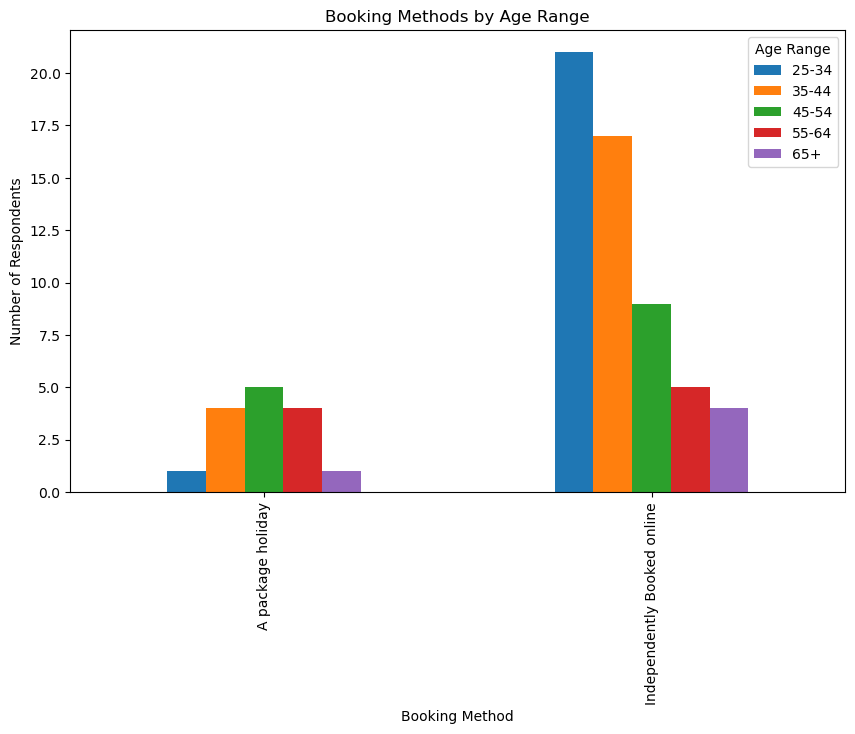

In [56]:
pivot_chart = pivot_bookings.drop(
    index="Total",
    errors="ignore").drop(
    columns="Total",
    errors="ignore")

pivot_chart.plot(
    kind="bar",
    figsize=(10,6))

plt.title("Booking Methods by Age Range")
plt.xlabel("Booking Method")
plt.ylabel("Number of Respondents")
plt.legend(title="Age Range")

plt.show()

## Analysis of Categorical Variables
### Review respondents by Age Range

In [57]:
df_age = df_Holidays['Age_Range'].value_counts()
df_age

Age_Range
25-34    22
35-44    21
45-54    14
55-64     9
65+       5
Name: count, dtype: int64

### Reindex the data to show in age range order

In [58]:
df_age = df_age.reindex( 
    ["25-34", "35-44", "45-54", "55-64", "65+"]
)

## Show Age Range Distribution in a Bar Chart

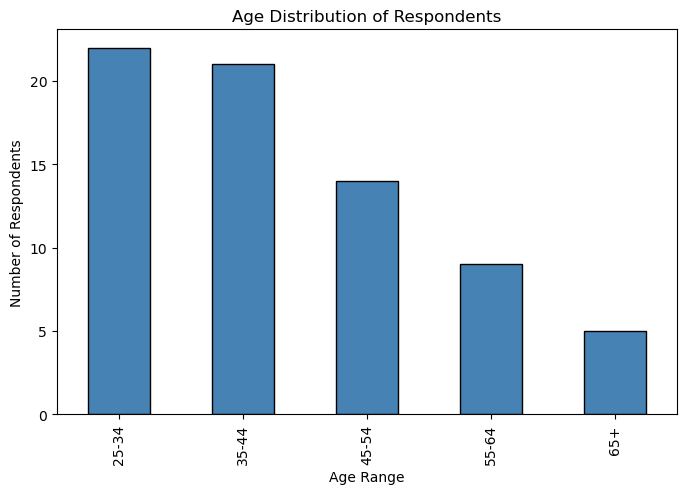

In [59]:
plt.figure(figsize=(8,5) )

df_age.plot.bar(
    color="steelblue",
    edgecolor="black")

plt.title("Age Distribution of Respondents")
plt.xlabel("Age Range")
plt.ylabel("Number of Respondents")

plt.show()



### The age distribution chart shows that respondents were reasonably evenly distributed across the younger and middle-age categories. The 25–34 and 35–44 age groups represented the largest proportion of respondents, while the 65+ category contained the fewest responses.

## Relationship to Holiday Duration, Total Expenditure & overall Satisfaction
### Use a scatterplot to visualise this multivariate analysis

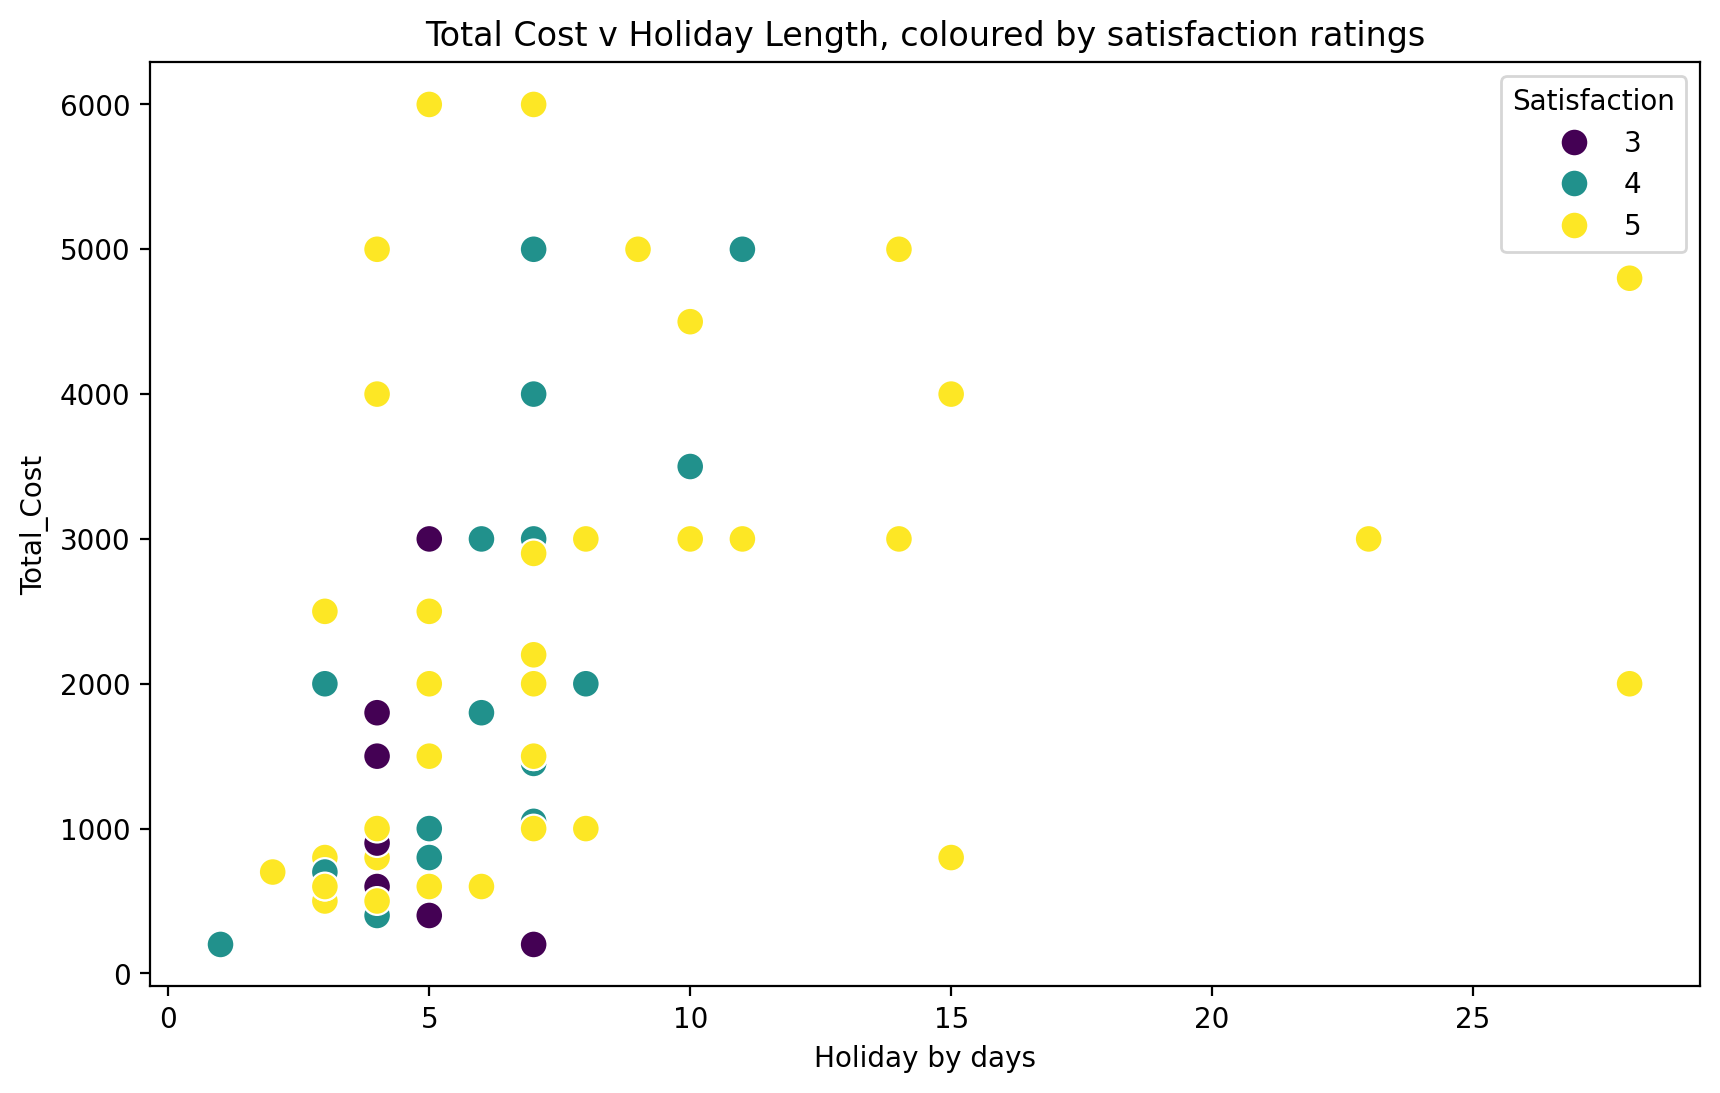

In [62]:
plt.figure(figsize=(10,6), dpi=200)

sns.scatterplot(
    data=df_Holidays,
    x='Holiday_Length',
    y='Total_Cost',
    hue="Satisfaction",
    palette="viridis",
    s=100)

plt.title("Total Cost v Holiday Length, coloured by satisfaction ratings")
plt.xlabel("Holiday by days")
plt.show()

### Understanding the scatterplot parameters
#### hue="Satisfaction" brings in a third variable
#### dpi and figsize allows you to sharpen the image and configure the size of the chart
#### palette="viridis" brings in ta colour scheme to visualise the dots
#### s=100 defines the size of the dots
####  Source:  https://www.udemy.com/course/python-for-machine-learning-data-science-masterclass/


## Scatterplot Analysis
####  We can see here that a high satisfaction rating occurs across all holiday costs
####  Although the more expensive holiday costs were mostly highly rated
####  Most holidays were in the 3-10 day range and as expected shorter holidays had the lower costs overall

## Travel By Air vs Total Cost

In [63]:
df_Holidays["Travel_By_Air"].value_counts()

Travel_By_Air
Yes    66
No      5
Name: count, dtype: int64

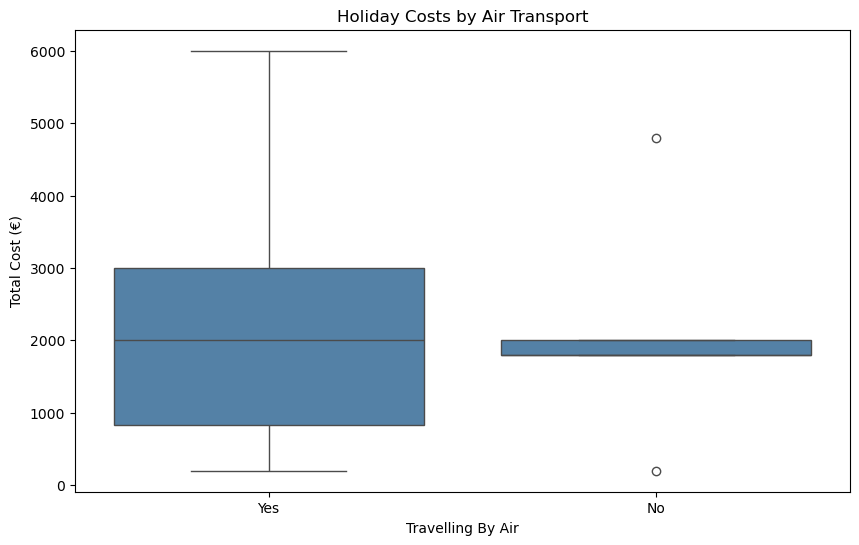

In [64]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df_Holidays,
    x= "Travel_By_Air",
    y= "Total_Cost",
    color="steelblue")

plt.title("Holiday Costs by Air Transport" )
plt.xlabel("Travelling By Air")
plt.ylabel("Total Cost (€)")

plt.show()

### Travel Analysis
####  Although the majority of the respondents choose to travel by air
####  We see that travelling by air generally incurred the higher overall costs

## Correlation and Outlier Analysis

### Cost Per Night Analysis

### Create a new Data Frame called GroupSize.  Take columns, Group_Size, Holiday_Length, Total_Cost & Satisfaction.  

# Derived Variables

### A new derived variable, Cost_Per_Night, was created by dividing Total_Cost by Holiday_Length, and again dividing by Group Size.  This gives a new metric for exploratory analysis, allowing holiday spending to be standarsised across all durations

In [65]:
df_Daily_Cost = df_Holidays[
    ["Age_Range","Group_Size", "Holiday_Length", "Total_Cost", "Satisfaction"] 
    ].copy()


In [66]:
# create an age order variable
age_order = ["25-34", "35-44", "45-54", "55-64", "65+"]

# when calling the Daily_Cost Dataframe, ensure that the age_order variable runs in the order declared above,
# using pandas Categorical function
df_Daily_Cost["Age_Range"] = pd.Categorical(
    df_Daily_Cost["Age_Range"],
    categories = age_order,
    ordered=True
)

In [67]:
df_Daily_Cost.head(3)

,Age_Range,Group_Size,Holiday_Length,Total_Cost,Satisfaction
0,65+,6,3,800,5
1,55-64,2,5,3000,3
2,65+,4,28,4800,5


### Create new column named Cost_Per_Niight

In [68]:
df_Daily_Cost["Cost_Per_Night"] = (
    (df_Daily_Cost["Total_Cost"] / 
    df_Daily_Cost["Holiday_Length"])/ df_Daily_Cost["Group_Size"]
)
df_Daily_Cost.head(5)

,Age_Range,Group_Size,Holiday_Length,Total_Cost,Satisfaction,Cost_Per_Night
0,65+,6,3,800,5,44.444444
1,55-64,2,5,3000,3,300.000000
2,65+,4,28,4800,5,42.857143
3,65+,6,3,500,5,27.777778
4,25-34,3,6,3000,5,166.666667


In [69]:
df_Daily_Cost.describe().T

,count,mean,std,min,25%,50%,75%,max
Group_Size,71.0,3.253521,1.754328,1.000000,2.00,3.000000,4.0,10.000000
Holiday_Length,71.0,7.267606,5.022685,1.000000,4.00,6.000000,7.5,28.000000
Total_Cost,71.0,2285.915493,1611.923941,200.000000,850.00,2000.000000,3000.0,6000.000000
Satisfaction,71.0,4.478873,0.673141,3.000000,4.00,5.000000,5.0,5.000000
Cost_Per_Night,71.0,128.360954,91.686411,5.333333,61.25,113.636364,150.0,428.571429


### Create a Pivot Table on the mean of the cost per night and compare with age range.  Plot the results on a Bar chart

In [70]:
pivot_Group = pd.pivot_table(
    df_Daily_Cost,
    values= "Cost_Per_Night",
    index="Age_Range",
    aggfunc="mean"
)

pivot_Group

C:\Users\ciara\AppData\Local\Temp\ipykernel_22704\4115464746.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_Group = pd.pivot_table(


,Cost_Per_Night
Age_Range,
25-34,107.768759
35-44,138.009264
45-54,145.449024
55-64,155.588624
65+,81.587302


# Data Visualisations

<Figure size 800x500 with 0 Axes>

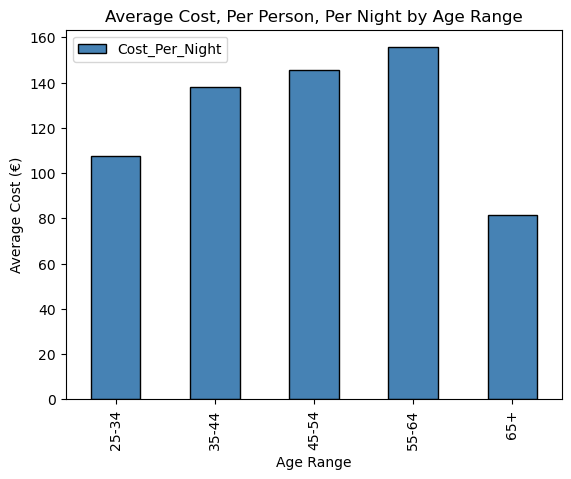

In [71]:
plt.figure(figsize=(8,5) )

pivot_Group.plot.bar(
    color="steelblue",
    edgecolor="black")

plt.title("Average Cost, Per Person, Per Night by Age Range")
plt.xlabel("Age Range")
plt.ylabel("Average Cost (€)")


plt.show()

#### The chart above shows that respondents aged 55-64 recorded the highest average cost per night (€155.58).
#### This was followed by respondents aged 45-54 (€145.44) and 35-44 (€138.09).
#### Respondents aged 65+ recorded the lowest cost per night (€81.58).
#### However caution is needed when interpreting the results due to the smaller sample size in the 65+ category

## Distribution of Average Cost Per Night Per Age Range

### The Boxplot below displays the distribution of Average Cost Per Night across each Age category
###

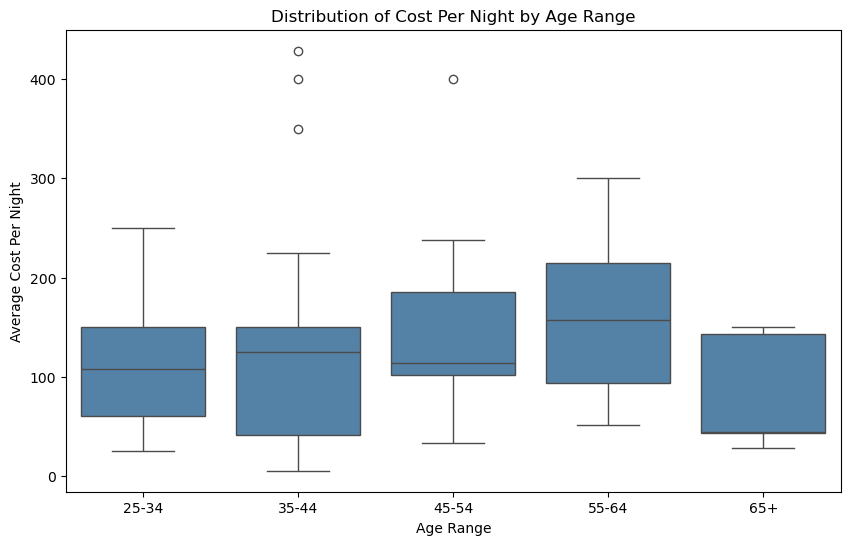

In [74]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df_Daily_Cost,
    x= df_Daily_Cost["Age_Range"],
    y= df_Daily_Cost["Cost_Per_Night"],
    order = age_order, # call the age_order variable created
    color="steelblue")

plt.title("Distribution of Cost Per Night by Age Range" )
plt.xlabel("Age Range")
plt.ylabel("Average Cost Per Night")

plt.show()

## Boxplot Analysis

### The presence of outliers helps explain why some age groups have noticeably higher mean values in the previous bar chart

## Distribution of Cost Per Night using Seaborn Library

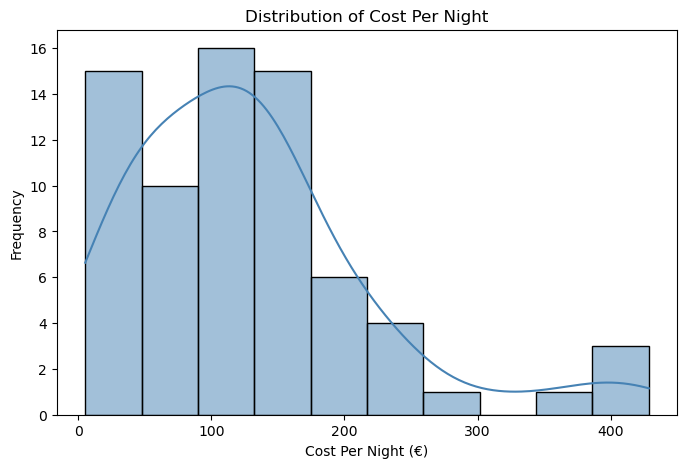

In [75]:
plt.figure(figsize=(8,5) )

sns.histplot(
    data=df_Daily_Cost,
    x="Cost_Per_Night",
    bins=10,
    kde=True,
    color="Steelblue"
)

plt.title("Distribution of Cost Per Night")
plt.xlabel("Cost Per Night (€)")
plt.ylabel("Frequency")


plt.show()



####  The histogram of Cost_Per_Night demonstrates a positively skewed distribution.
####  Most respondents recorded a cost per night below €200, whilst a smaller number of respondents reported a significantly higher spending.
####  The presence of these higher values creates a longer tail on the right hand side of the distribution, indicating potential outliers.

# Correlation Analysis

### Create a Correlation Matriix using Numeric Variables

In [92]:
corr_matrix = df_Daily_Cost.corr(numeric_only=True)
corr_matrix

,Group_Size,Holiday_Length,Total_Cost,Satisfaction,Cost_Per_Night
Group_Size,1.000000,0.112164,0.145762,0.089281,-0.405800
Holiday_Length,0.112164,1.000000,0.360254,0.240427,-0.268741
Total_Cost,0.145762,0.360254,1.000000,0.253824,0.518038
Satisfaction,0.089281,0.240427,0.253824,1.000000,0.097317
Cost_Per_Night,-0.405800,-0.268741,0.518038,0.097317,1.000000


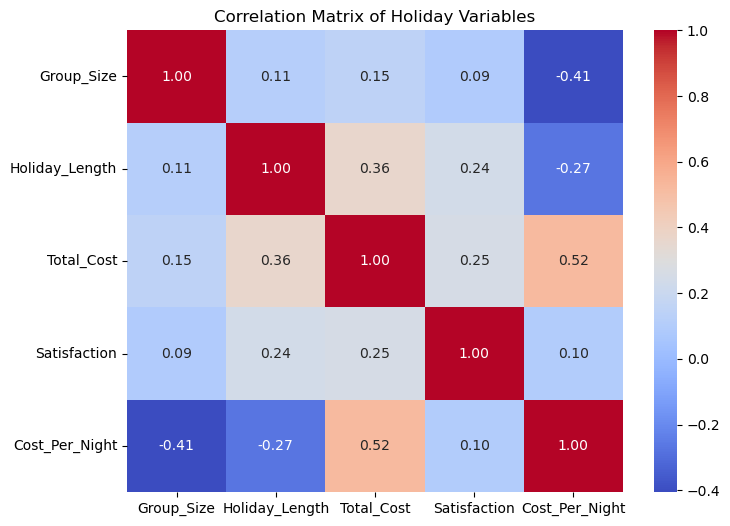

In [93]:
# create a seaborn heatmap
plt.figure(figsize=(8,6) )

sns.heatmap(
    corr_matrix,  
    annot=True,   
    cmap="coolwarm",  
    fmt=".2f" )      

plt.title("Correlation Matrix of Holiday Variables")

plt.show()

## Understanding of the Heatmap Parameters
### The heatmap is built using the Seaborn library, which is also built on Matplotlib
#### figsize creates an 8 x 6 inch chart
#### corr_matrix supplies the correlation coefficients
#### annot=True displays the coefficients inside the heatmap cells
#### cmap="coolwarm" applies a colour scheme that highlights positive and negative relationships
#### fmt=".2f" displays values to 2 decimal places
#### plt.title() add a descriptive chart title
#### plt.show() renders the visualisation

## Correlation Findings

#### The strongest positive correlation was between Total_Cost and Cost_Per_Night (r=0.52)
#### This indicates that respondents who spent more overall also tended to spend more on a per-night basis, which is to be expected.
#### A more moderate correlation (r=0.36) was between Holiday_Length and Total_Cost, suggesting that longer holidays resulted in higher overall costs.
#### Satisfaction levels displayed weak positive correlation with the other variables, indicating that higher spending doesn't necessarily lead to higher satisfaction.
#### A weak negative correlation (r = -0.27) was found between Holiday_Length and Cost_Per_Night, indicating that longer holidays can have a lower average daily cost

## Outlier Analysis using Accomodation Costs

### Original Question on accomodation costs
####  Approximately how much did your accommodation cost per room per night (€)?"

## Create a Boxplot of Accommodation Costs

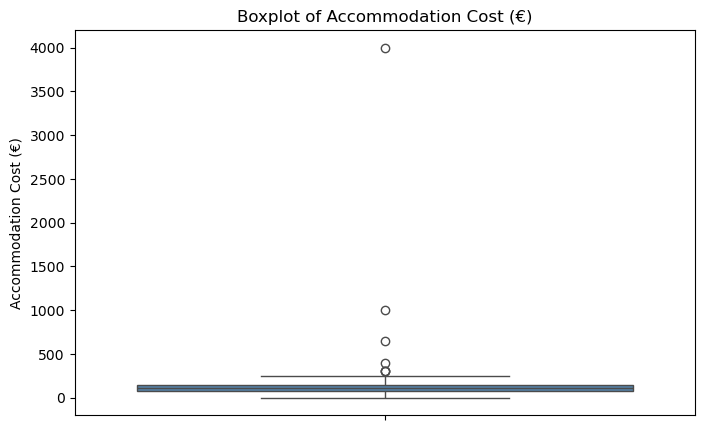

In [94]:
plt.figure(figsize=(8,5) )

sns.boxplot(
    y=df_Holidays["Accommodation_Cost"],
    color="steelblue")

plt.title("Boxplot of Accommodation Cost (€)" )

plt.ylabel("Accommodation Cost (€)")

plt.show()

## Understanding the Boxplot Parameters
#### sns.boxplot() creates a box-and-whisker plot using the Seaborn library
#### y=df_Holidays["Accommodation_Cost"] identifies the variable from the data frame to be plotted on the vertical axis
#### color="steelblue" applies the blue colour scheme to improve readability
#### plt.title adds the descriptive title to the chart
#### plt.ylabel Adds a label to the y-axis

# Boxplot Analysis

#### The Boxplot clearly shows the presence of several extreme accommodation costs.
#### These values lie beyond the upper whisker of the distribution and would be considered potential outliers

### Create a new dataFrame to remove outliers

In [95]:
df_Accom = df_Holidays[
    ["Age_Range","Group_Size", "Holiday_Length", "Accommodation_Cost", "Satisfaction"] 
    ].copy()


In [96]:
df_Accom.head(5)

,Age_Range,Group_Size,Holiday_Length,Accommodation_Cost,Satisfaction
0,65+,6,3,100,5
1,55-64,2,5,150,3
2,65+,4,28,70,5
3,65+,6,3,50,5
4,25-34,3,6,115,5


In [97]:
df_Accom["Accommodation_Cost"].describe()

count      71.000000
mean      198.295775
std       478.726686
min         1.000000
25%        80.000000
50%       115.000000
75%       150.000000
max      4000.000000
Name: Accommodation_Cost, dtype: float64

In [98]:
len(df_Holidays["Accommodation_Cost"])

71

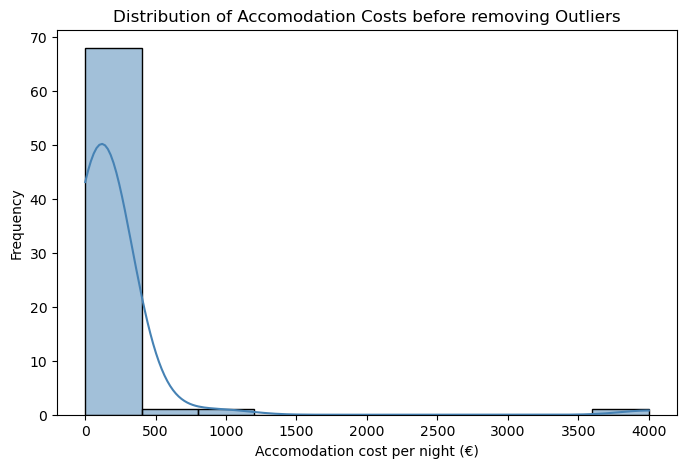

In [99]:
plt.figure(figsize=(8,5) )

sns.histplot(
    data=df_Accom,
    x="Accommodation_Cost",
    bins=10,
    kde=True,
    color="Steelblue"
)

plt.title("Distribution of Accomodation Costs before removing Outliers")
plt.xlabel("Accomodation cost per night (€)")
plt.ylabel("Frequency")


plt.show()

### Drop Outliers in Accomodation Costs using the IQR Method

In [100]:
Q1 = df_Accom["Accommodation_Cost"].quantile(0.25)
Q3 = df_Accom["Accommodation_Cost"].quantile(0.75)
IQR = Q3 - Q1
print("Q1= " , Q1)
print("Q3= " , Q3)
print("IQR= " , IQR)

Q1=  80.0
Q3=  150.0
IQR=  70.0


In [101]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("lower_bound =  " , lower_bound)
print("upper_bound =  " , upper_bound)



lower_bound =   -25.0
upper_bound =   255.0


### remove the lower and upper bounds

In [102]:
df_Accom = df_Accom[
    (df_Accom["Accommodation_Cost"] >= lower_bound) &
     (df_Accom["Accommodation_Cost"] <= upper_bound)
      ]

In [103]:
df_Accom["Accommodation_Cost"].describe()

count     64.000000
mean     111.390625
std       54.590719
min        1.000000
25%       67.500000
50%      100.000000
75%      150.000000
max      250.000000
Name: Accommodation_Cost, dtype: float64

#### The mean accommodation costs of €111.39 is recorded after removal of outliers
####  The original dataset has a mean of €198.28 before removal of outliers
####  This further indicates that a small number of observations were increasing the average cost

In [104]:
After_Removal = len(df_Accom["Accommodation_Cost"])

In [105]:
print("The total number of rows before removing Outliers: ", len(df_Holidays["Accommodation_Cost"]))
print("The total number of rows after removing Outliers: ", len(df_Accom["Accommodation_Cost"]))

The total number of rows before removing Outliers:  71
The total number of rows after removing Outliers:  64


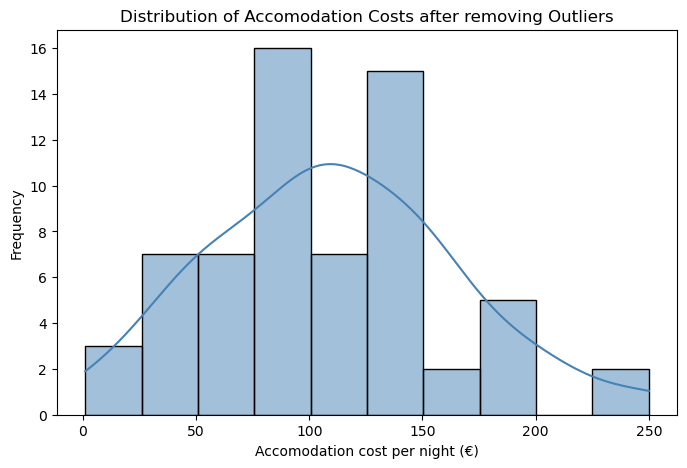

In [106]:
plt.figure(figsize=(8,5) )

sns.histplot(
    data=df_Accom,
    x="Accommodation_Cost",
    bins=10,
    kde=True,
    color="Steelblue"
)

plt.title("Distribution of Accomodation Costs after removing Outliers")
plt.xlabel("Accomodation cost per night (€)")
plt.ylabel("Frequency")


plt.show()


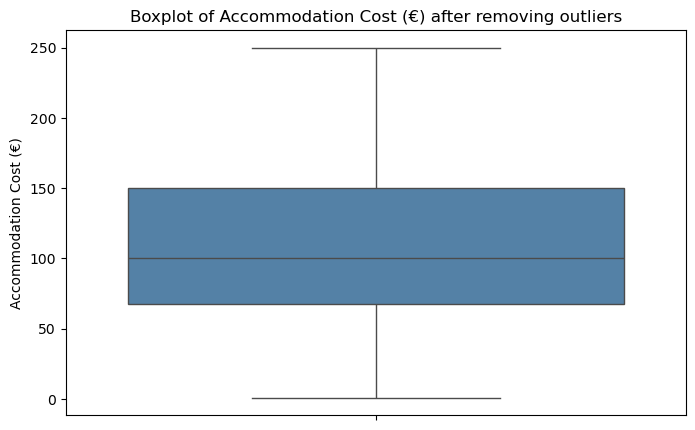

In [107]:
plt.figure(figsize=(8,5) )

sns.boxplot(
    y=df_Accom["Accommodation_Cost"],
    color="steelblue")

plt.title("Boxplot of Accommodation Cost (€) after removing outliers" )

plt.ylabel("Accommodation Cost (€)")

plt.show()

### Using the IQR Method to identify outliers with the Accommodation Cost variable
#### Q1 was 80
#### Q3 was 150
####  IQR was 70

#### By applying the standard 1.5 x IQR the upper bound was €255 and the lower bound was €-25 were calculated
####  Therefore only Rows exceeding the upper bounds were classified as outliers and removed 
####  This resulted in seven observations classified as outliers and removed, with a new dataset of 64 remaining.
####  A new distribution chart and Boxplot were created to visualise the dataset without outliers
